# Week 2 · Forecasting MLB hitter breakouts

The task is to rank hitters by the probability that their following-season FanGraphs wRC+ increases by at least 20 points. The project reuses the Week 1 binary label derived from unrounded wRC+. The cohort requires at least 300 PA in each season, so the results describe historical outcomes among hitters who qualified in both years.

Run `python -m src.train_models` and `python -m src.evaluate_models` from the repository root to produce the artifacts used below.

In [1]:
import json
from pathlib import Path
import sys

import pandas as pd
from IPython.display import Image, display

root = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "src/feature_sets.py").is_file())
sys.path.insert(0, str(root))

from src.feature_sets import FEATURE_SETS
from src.train_models import EXPERIMENTS, METRIC_DIR, PREDICTION_DIR, THRESHOLD
from src.evaluate_models import FIGURE_DIR, SELECTION

## Dataset and chronological split

Training uses the 2017, 2018, 2021 and 2022 feature seasons. Validation uses 2023 features and 2024 outcomes. The final holdout uses 2024 features and 2025 outcomes. The shortened 2020 season leaves both adjacent transitions without qualifying observations. A hitter may appear in multiple years, with a single row per player-season. The holdout appears below only as aggregate split metadata.

In [2]:
split = pd.read_csv(METRIC_DIR / "week2_split_summary.csv")
display(split.style.format({"prevalence": "{:.2%}"}))

,split,feature_seasons,outcome_seasons,observations,positives,prevalence
0,train,"2017, 2018, 2021, 2022","2018, 2019, 2022, 2023",800,128,16.00%
1,validation,2023,2024,207,36,17.39%
2,test,2024,2025,199,24,12.06%


## Predictor groups and fitting protocol

Only season-t predictors from the Week 1 allowlist enter the models. Median imputation is fitted on training observations inside each pipeline. Logistic regression also standardizes numerical features using training statistics. All experiments share the same chronological membership and preserve the observed class balance.

In [3]:
display(pd.Series({name: ", ".join(columns) for name, columns in FEATURE_SETS.items()},
                  name="Season-t predictors").to_frame())
metrics = pd.read_csv(METRIC_DIR / "week2_model_comparison.csv").set_index("experiment")
scores = ["ap", "roc_auc", "precision", "recall", "f1", "precision_at_20", "brier"]

,Season-t predictors
baseline,"age, wrc_plus"
traditional,"age, pa, wrc_plus, woba, iso, babip, bb_rate, ..."
traditional_statcast,"age, pa, wrc_plus, woba, iso, babip, bb_rate, ..."


## M1 · Age and starting wRC+ establish a parsimonious reference for all fitted classifiers.

In [4]:
display(metrics.loc[["M1"], scores].round(4))

,ap,roc_auc,precision,recall,f1,precision_at_20,brier
experiment,,,,,,,
M1,0.4637,0.7156,0.75,0.0833,0.15,0.6,0.125


## M2 · The traditional bundle adds playing time, offensive production and plate-discipline statistics to the baseline.

In [5]:
display(metrics.loc[["M2"], scores].round(4))

,ap,roc_auc,precision,recall,f1,precision_at_20,brier
experiment,,,,,,,
M2,0.484,0.7558,0.8,0.1111,0.1951,0.55,0.1208


## M3 · Six Statcast variables augment the traditional bundle. Comparing M2 with M3 holds the classifier family and observations fixed.

In [6]:
display(metrics.loc[["M3"], scores].round(4))

,ap,roc_auc,precision,recall,f1,precision_at_20,brier
experiment,,,,,,,
M3,0.4508,0.8028,0.4615,0.1667,0.2449,0.5,0.12


## M4 · The forest uses 300 trees with maximum depth 6 and a minimum of 5 observations per leaf. The seed is 42.

In [7]:
display(metrics.loc[["M4"], scores].round(4))

,ap,roc_auc,precision,recall,f1,precision_at_20,brier
experiment,,,,,,,
M4,0.4472,0.7365,0.6667,0.0556,0.1026,0.6,0.1233


## M5 · The forest configuration stays fixed while adding the same six Statcast variables, enabling a paired comparison with M4.

In [8]:
display(metrics.loc[["M5"], scores].round(4))

,ap,roc_auc,precision,recall,f1,precision_at_20,brier
experiment,,,,,,,
M5,0.4819,0.7718,0.0,0.0,0.0,0.55,0.1213


## Validation performance and ranking

Average Precision (AP) summarizes ranking performance with an emphasis on the minority class. A constant probability equal to training prevalence has validation AP equal to validation prevalence. Classification metrics use the fixed 0.50 cutoff. When a model predicts zero positives, precision is undefined and reported as zero; its recall and F1 are also zero. Precision@20 treats all twenty ranked hitters as breakout candidates.

,ap,roc_auc,precision,recall,f1,precision_at_20,brier
experiment,,,,,,,
M1,0.4637,0.7156,0.7500,0.0833,0.1500,0.60,0.1250
M2,0.4840,0.7558,0.8000,0.1111,0.1951,0.55,0.1208
M3,0.4508,0.8028,0.4615,0.1667,0.2449,0.50,0.1200
M4,0.4472,0.7365,0.6667,0.0556,0.1026,0.60,0.1233
M5,0.4819,0.7718,0.0000,0.0000,0.0000,0.55,0.1213
constant,0.1739,0.5000,0.0000,0.0000,0.0000,0.20,0.1439


Validation winner by AP: M2 (0.4840)


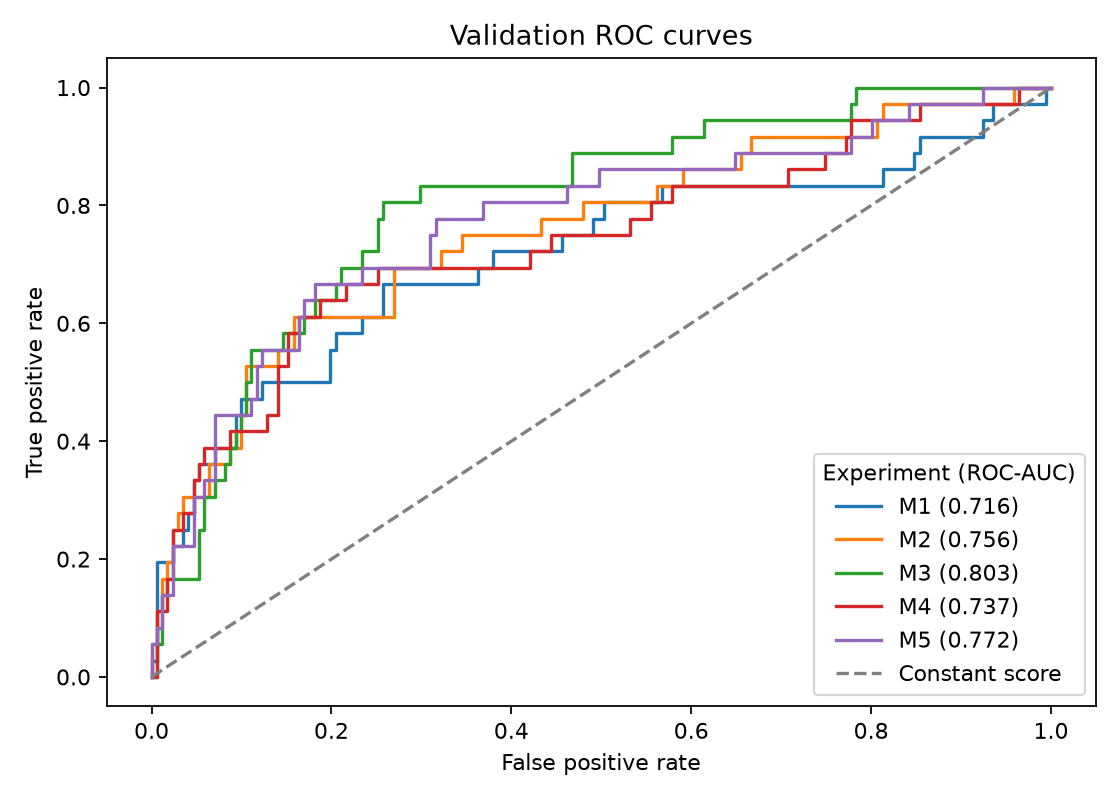

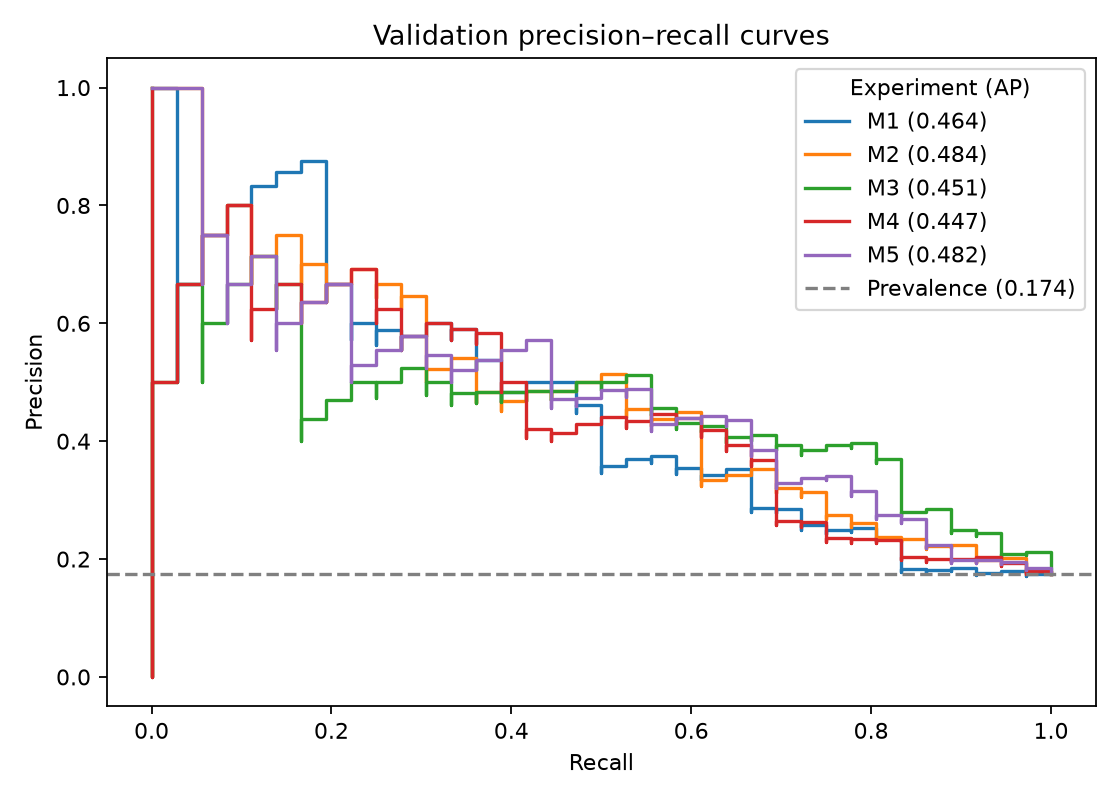

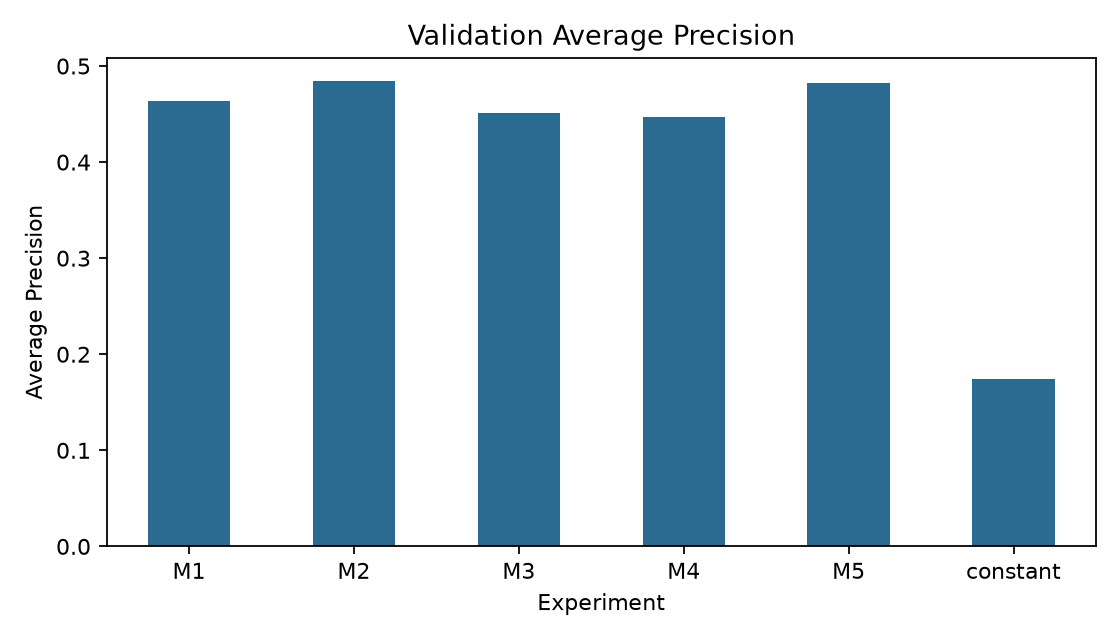

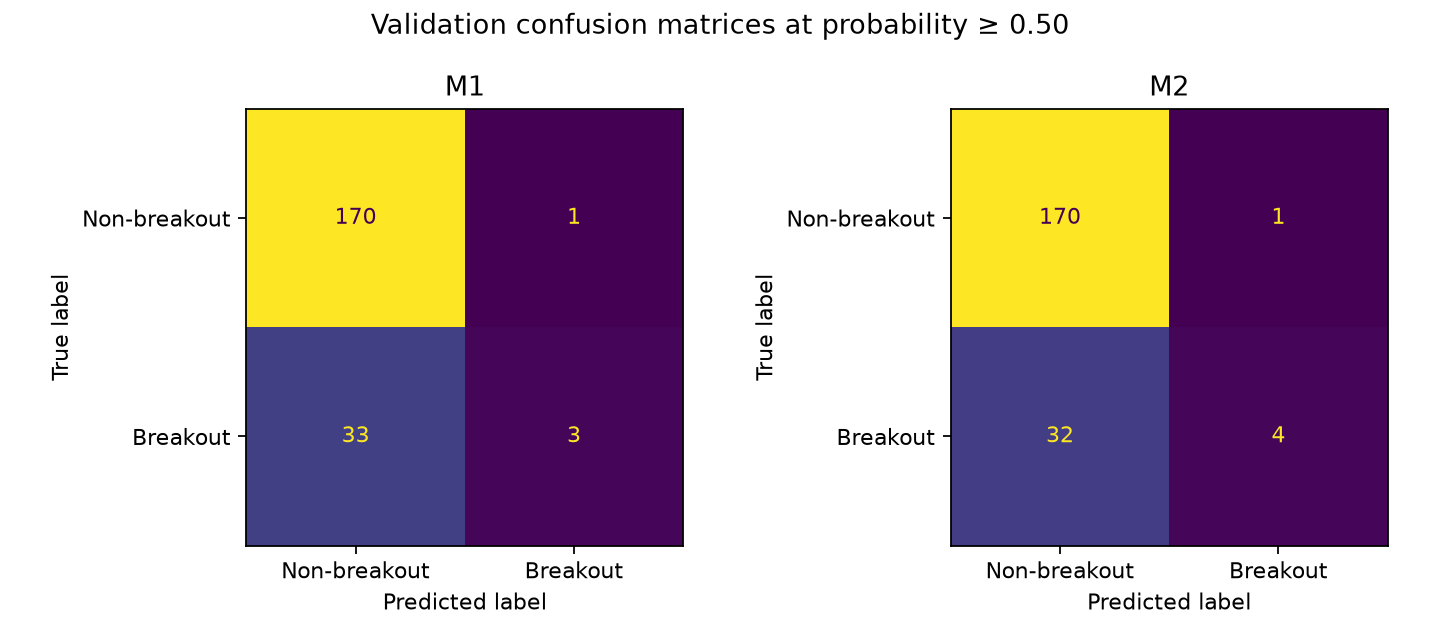

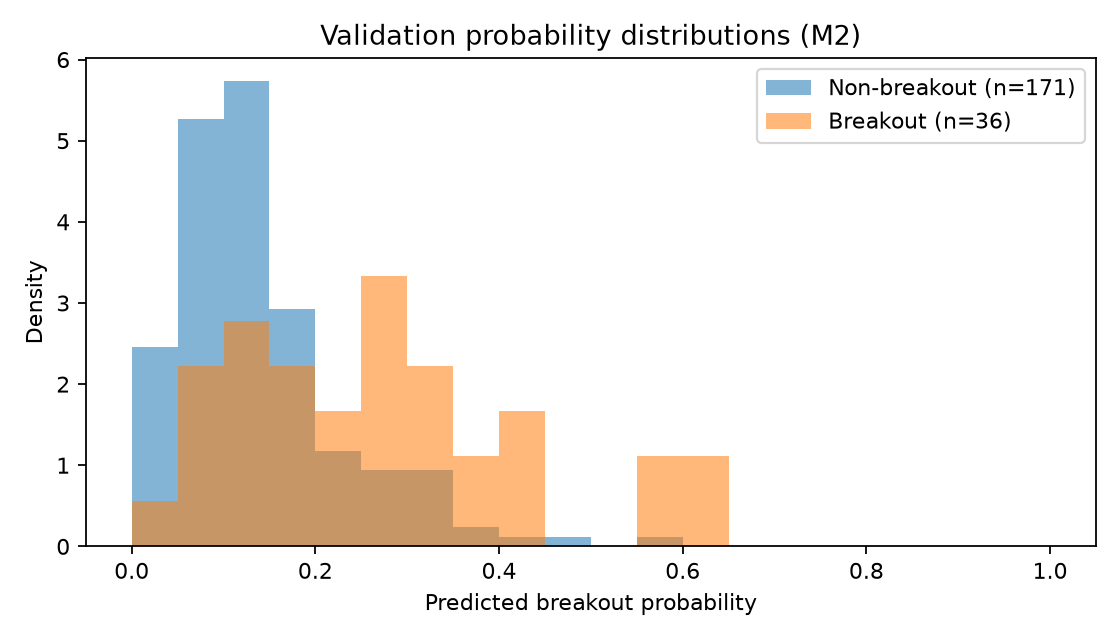

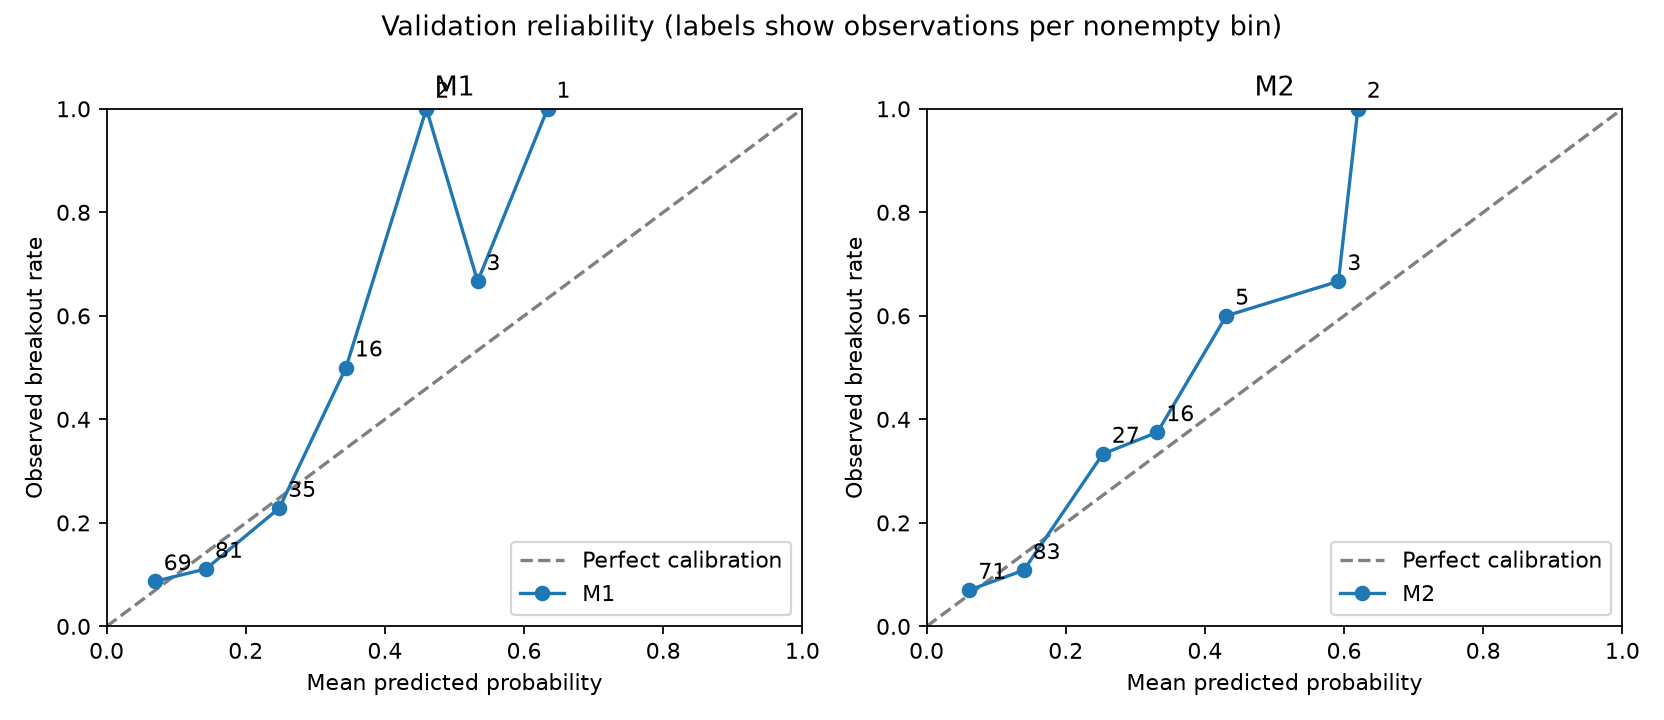

In [9]:
selection = json.loads((METRIC_DIR / SELECTION).read_text())
assert selection["threshold"] == THRESHOLD
display(metrics.loc[[*EXPERIMENTS, "constant"], scores].round(4))
print(f"Validation winner by AP: {selection['experiment']} ({selection['validation_ap']:.4f})")
for name in ("roc_curves", "precision_recall_curves", "average_precision", "confusion_matrices",
             "probability_distributions", "calibration"):
    display(Image(filename=str(FIGURE_DIR / f"{name}.png"), width=660))

## Traditional versus Statcast

Each delta subtracts the traditional-only metric from the metric after adding Statcast. A negative Brier delta indicates lower squared probability error. Interpret changes together across metrics. The validation sample spans one outcome season, so the direction and size of these differences could vary in other years.

,model_name,traditional,with_statcast,delta_ap,delta_roc_auc,delta_brier,delta_precision_at_20,delta_recall
0,Logistic Regression,M2,M3,-0.0332,0.0469,-0.0008,-0.05,0.0556
1,Random Forest,M4,M5,0.0348,0.0353,-0.0020,-0.05,-0.0556


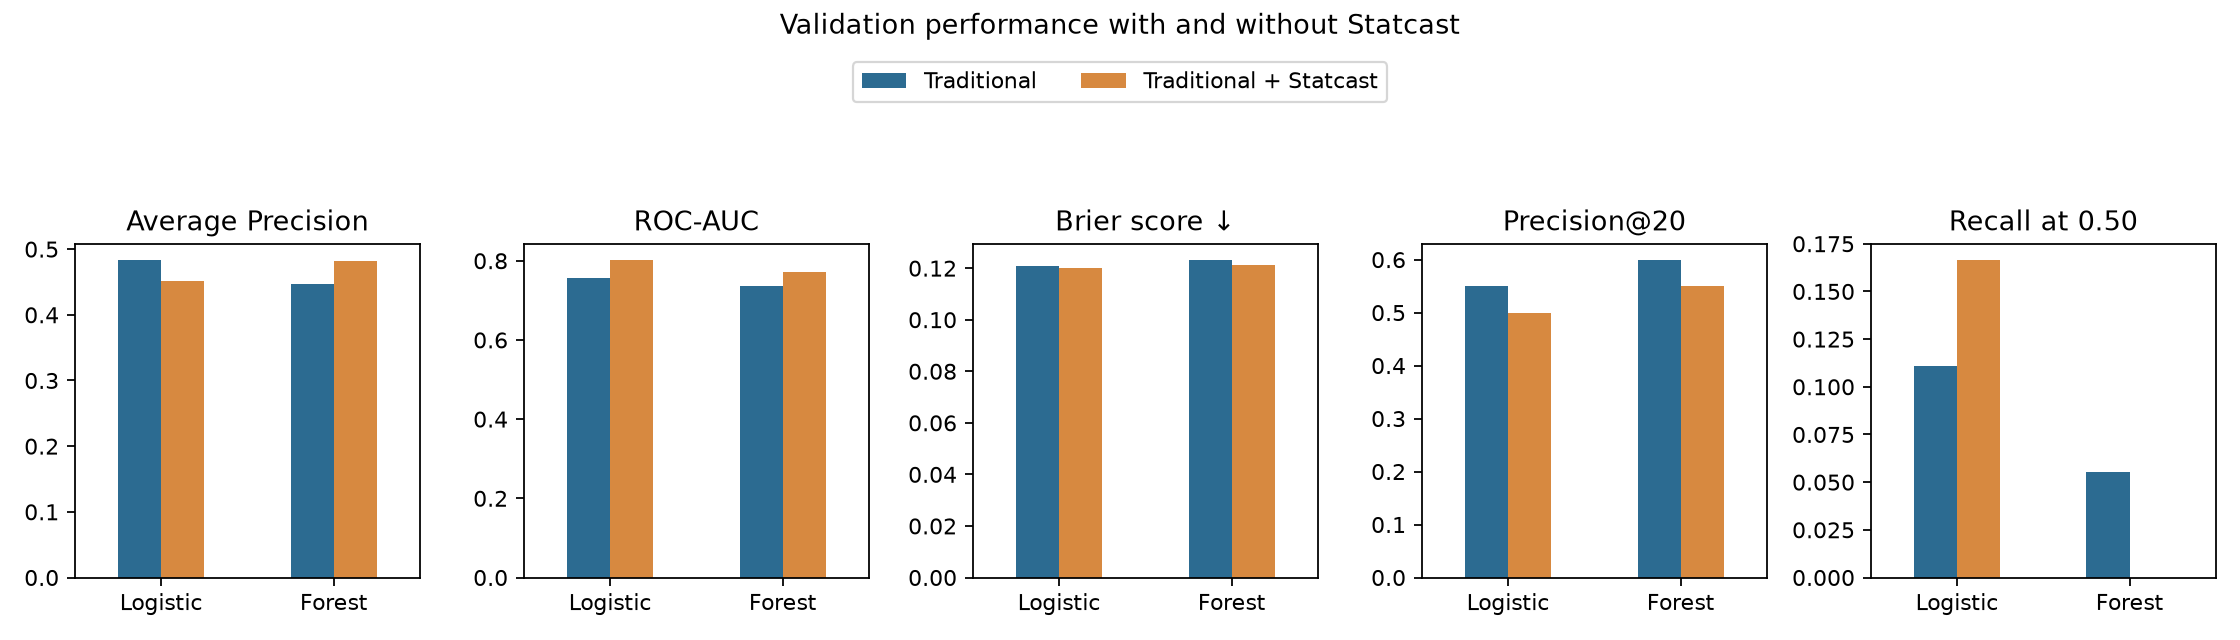

In [10]:
display(pd.read_csv(METRIC_DIR / "week2_statcast_comparison.csv").round(4))
display(Image(filename=str(FIGURE_DIR / "statcast_comparison.png"), width=900))

## Retrospective top 20

The leaderboard uses the frozen validation winner. The correctness column evaluates the 0.50 class prediction. A ranked hitter can be a top-20 candidate even when their probability is below 0.50.

In [11]:
leaders = pd.read_csv(PREDICTION_DIR / "validation_top20.csv")
display(leaders[["rank", "player_name", "season", "wrc_plus", "predicted_probability",
                 "next_season_wrc_plus", "wrc_plus_change", "breakout", "correct_at_0_50"]].round(3))

,rank,player_name,season,wrc_plus,predicted_probability,next_season_wrc_plus,wrc_plus_change,breakout,correct_at_0_50
0,1,Brenton Doyle,2023,44.282,0.626,97.775,53.493,1,True
1,2,Brice Turang,2023,61.416,0.614,88.437,27.021,1,True
2,3,Nick Fortes,2023,51.964,0.598,58.232,6.268,0,False
3,4,Gavin Sheets,2023,61.574,0.592,88.782,27.208,1,True
4,5,Oswaldo Cabrera,2023,59.286,0.585,87.837,28.551,1,True
5,6,Anthony Volpe,2023,83.283,0.495,86.144,2.862,0,True
6,7,JJ Bleday,2023,90.577,0.432,120.044,29.467,1,False
7,8,Michael Massey,2023,73.942,0.417,103.538,29.596,1,False
8,9,Daulton Varsho,2023,84.352,0.408,98.513,14.161,0,True
9,10,Ezequiel Tovar,2023,71.886,0.401,95.371,23.485,1,False


## Limitations and Week 3

The retrospective next-season PA requirement conditions on future playing time. A +20 wRC+ change can end below the league-average mark of 100, and regression to the mean can contribute to the relationship with starting wRC+. Class imbalance, repeated hitters, the missing 2020 transitions and the small number of seasons limit generalization and calibration assessment.

Week 3 will examine gradient boosting, expanding-window backtesting, age-group evaluation, feature importance, false-positive and false-negative case studies, and calibration improvements. The 2025 outcomes remain reserved for an explicit final evaluation.